Accuracy Without Pruning: 0.9853658536585366


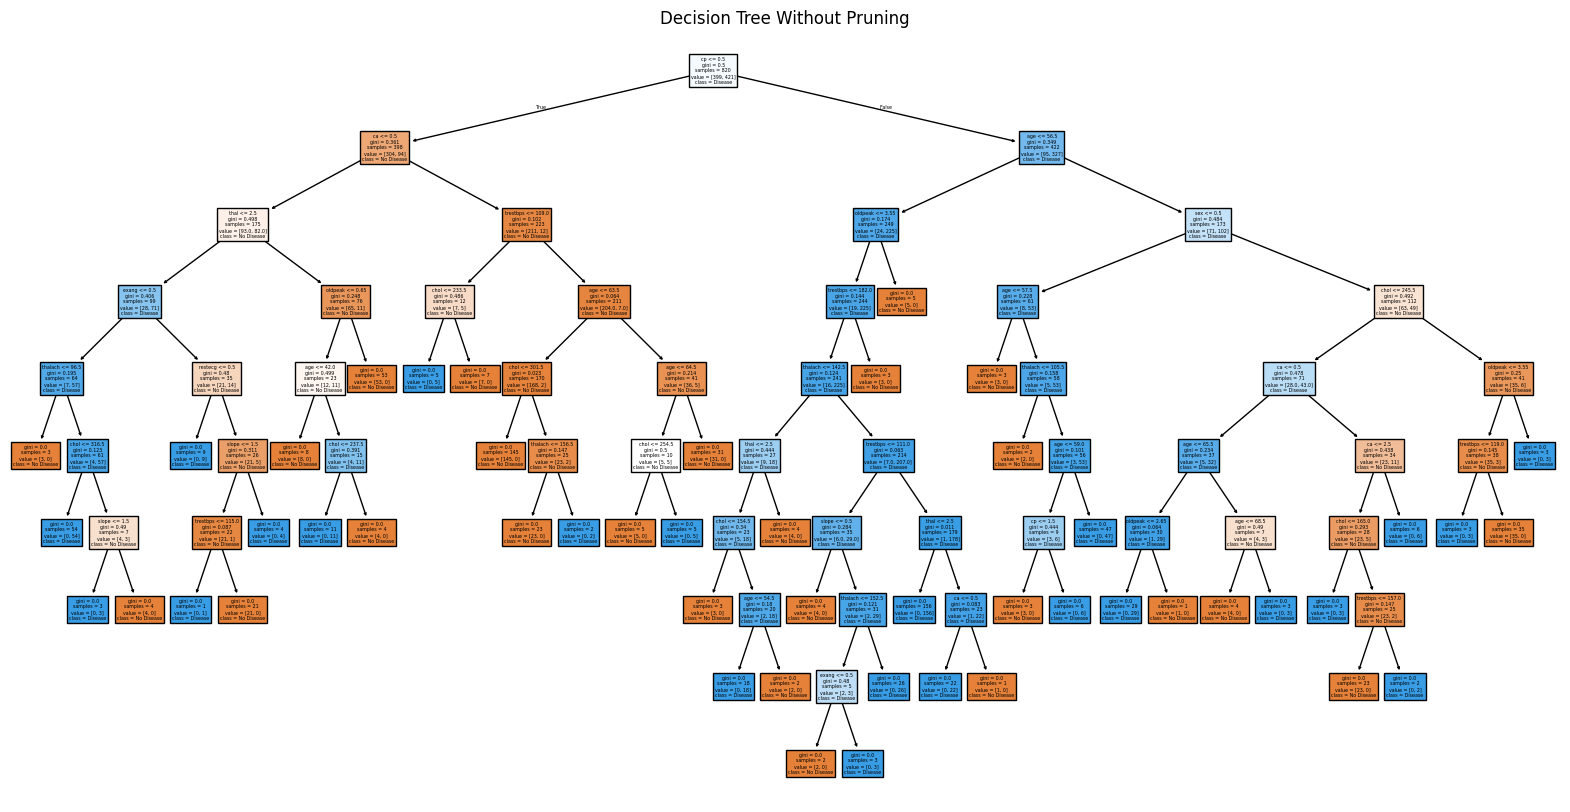

Accuracy With Pruning: 0.8390243902439024


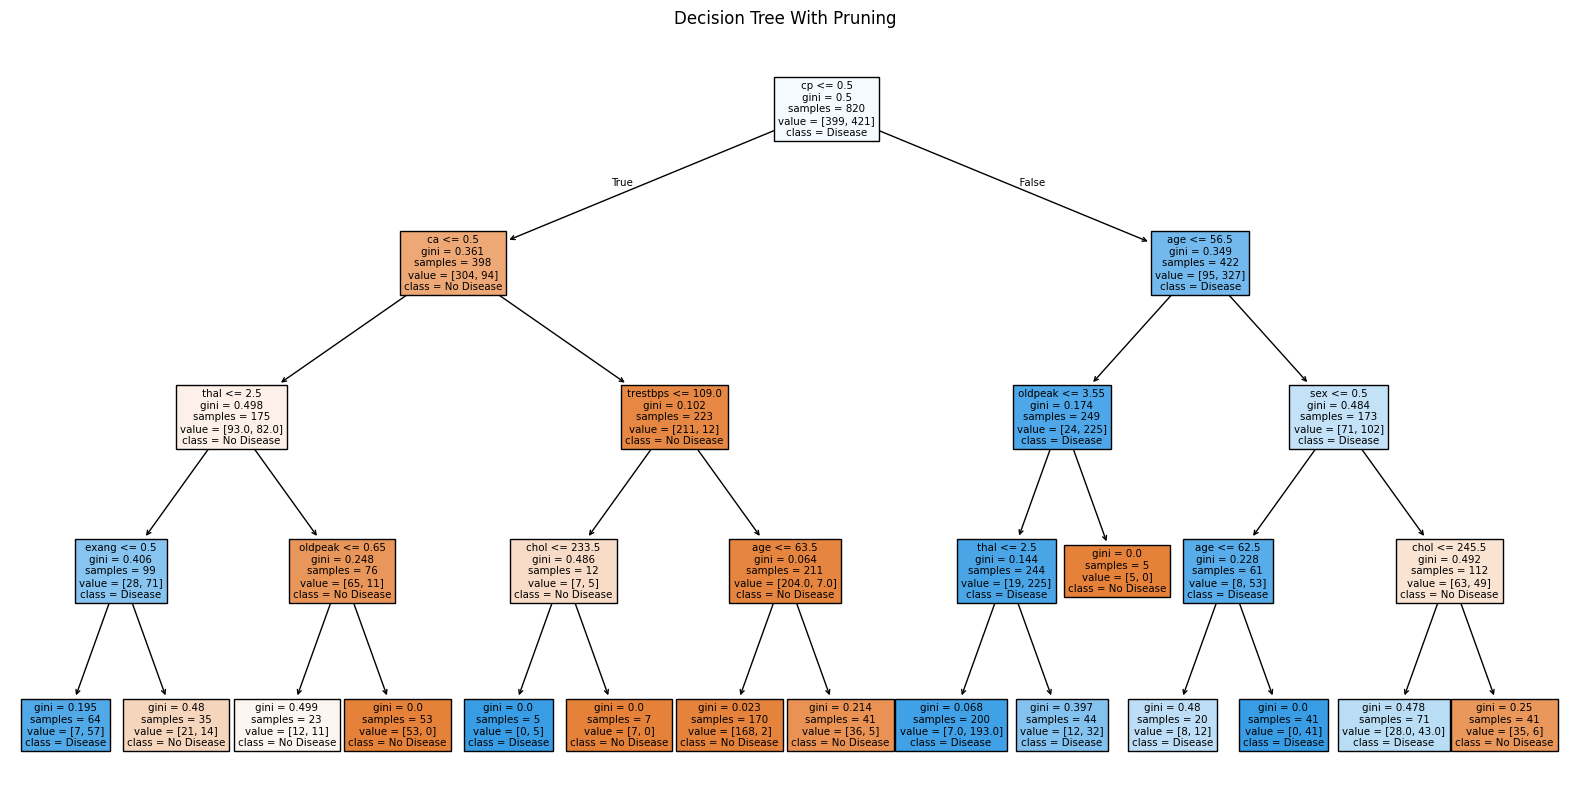


Feature Importance:
     Feature  Importance
2         cp    0.437861
11        ca    0.124255
12      thal    0.118797
0        age    0.092947
4       chol    0.061874
9    oldpeak    0.057716
1        sex    0.054128
8      exang    0.040121
3   trestbps    0.012301
7    thalach    0.000000
6    restecg    0.000000
5        fbs    0.000000
10     slope    0.000000

Accuracy Comparison
Without Pruning: 0.9853658536585366
With Pruning: 0.8390243902439024


In [4]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score

# Load dataset
data = pd.read_csv("heart.csv")

# Separate features and target
X = data.drop("target", axis=1)
y = data["target"]

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Decision Tree without pruning
tree1 = DecisionTreeClassifier(
    criterion="gini", random_state=42
)
tree1.fit(X_train, y_train)

prediction1 = tree1.predict(X_test)
accuracy1 = accuracy_score(y_test, prediction1)

print("Accuracy Without Pruning:", accuracy1)

# Visualize tree
plt.figure(figsize=(20, 10))
plot_tree(
    tree1,
    feature_names=X.columns,
    class_names=["No Disease", "Disease"],
    filled=True
)
plt.title("Decision Tree Without Pruning")
plt.show()

# Decision Tree with pruning
tree2 = DecisionTreeClassifier(
    criterion="gini",
    max_depth=4,
    min_samples_leaf=5,
    random_state=42
)
tree2.fit(X_train, y_train)

prediction2 = tree2.predict(X_test)
accuracy2 = accuracy_score(y_test, prediction2)

print("Accuracy With Pruning:", accuracy2)

# Visualize pruned tree
plt.figure(figsize=(20, 10))
plot_tree(
    tree2,
    feature_names=X.columns,
    class_names=["No Disease", "Disease"],
    filled=True
)
plt.title("Decision Tree With Pruning")
plt.show()

# Feature Importance
importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": tree2.feature_importances_
})

print("\nFeature Importance:")
print(importance.sort_values(by="Importance", ascending=False))

# Accuracy comparison
print("\nAccuracy Comparison")
print("Without Pruning:", accuracy1)
print("With Pruning:", accuracy2)